# Аналіз експерименту main-60s

Інтерактивний перегляд результатів бенчмарку. Усі обчислення — у модулі `vrp_analysis.py`; той самий модуль з командного рядка зберігає таблиці й рисунки для статті:

```
python analysis/vrp_analysis.py results/main-60s
```

Запуск ноутбука: **Run All**. Шляхи вказано відносно папки `analysis`.

In [1]:
%matplotlib inline
import pandas as pd
import vrp_analysis as va

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
EXPERIMENT = '../results/main-60s'
CONVERGENCE = '../results/conv-60s'  # окремий прогін для кривих збіжності; None — криві з EXPERIMENT

exp = va.load(EXPERIMENT)
curves = va.load(CONVERGENCE) if CONVERGENCE else exp
print(len(exp.runs), 'запусків,', exp.runs.instance.nunique(), 'задач, алгоритми:', exp.algorithms)

1736 запусків, 56 задач, алгоритми: ['i1-ls', 'sa', 'alns', 'ortools']


## 1. Підсумок

CNV / CTD — сумарна кількість машин / сумарна відстань по всіх задачах. Геп за відстанню має сенс лише там, де кількість машин збігається з BKS.

In [2]:
va.summary_table(exp)

,CNV (середнє за seed),CNV (найкращий з seed),CTD (середнє за seed),"Задач, де найкращий запуск має к-сть машин BKS","Запусків з к-стю машин BKS, %","Геп на цих запусках, % (середнє)","Геп на цих запусках, % (медіана)","Геп на 27 спільних задачах, %",Ітерацій за запуск (медіана)
I1 + LS,449.00,449.00,"59,932.25",27.00,48.21,5.21,1.89,5.21,NaN
SA,430.20,427.00,"55,817.48",34.00,56.79,0.29,0.00,0.27,"421,540,096.00"
ALNS,407.60,405.00,"57,560.25",56.00,95.36,0.87,0.18,0.39,"210,160.50"
OR-Tools,430.60,427.00,"57,602.77",36.00,61.25,2.42,2.62,2.18,NaN
BKS,405.00,405.00,"57,186.89",56.00,NaN,NaN,NaN,NaN,NaN


## 2. Результати за класами Solomon

NV — середня кількість машин на задачу класу, TD — середня відстань.

In [3]:
va.class_table(exp)

I1 + LS               SA             ALNS           OR-Tools  \
               NV        TD     NV        TD     NV        TD       NV   
class                                                                    
C1          10.00    833.53  10.00    828.38  10.00    828.38    10.00   
C2           3.00    600.08   3.00    589.86   3.00    589.86     3.00   
R1          13.50  1,267.44  12.72  1,186.66  12.01  1,215.51    12.73   
R2           3.18  1,017.67   3.18    920.95   2.74    965.51     3.09   
RC1         13.38  1,453.10  12.19  1,352.76  11.68  1,381.74    12.85   
RC2          3.88  1,200.16   3.88  1,056.36   3.25  1,140.67     3.38   
CNV / CTD  449.00 59,932.25 430.20 55,817.48 407.60 57,560.25   430.60   

                       BKS            
                 TD     NV        TD  
class                                 
C1           847.22  10.00    828.38  
C2           590.27   3.00    589.86  
R1         1,213.68  11.92  1,210.34  
R2           948.01   2.73    951.03  
RC1        1,392.96  11.50  1,384.16  
RC2        1,139.95   3.25  1,119.24  
CNV / CTD 57,602.77 405.00 57,186.89

In [4]:
va.class_table(exp, best=True)

I1 + LS               SA             ALNS           OR-Tools  \
               NV        TD     NV        TD     NV        TD       NV   
class                                                                    
C1          10.00    833.53  10.00    828.38  10.00    828.38    10.00   
C2           3.00    600.08   3.00    589.86   3.00    589.86     3.00   
R1          13.50  1,267.44  12.58  1,185.79  11.92  1,212.27    12.67   
R2           3.18  1,017.67   3.18    915.50   2.73    956.63     3.09   
RC1         13.38  1,453.10  12.00  1,349.18  11.50  1,386.19    12.50   
RC2          3.88  1,200.16   3.88  1,051.92   3.25  1,123.91     3.38   
CNV / CTD  449.00 59,932.25 427.00 55,683.11 405.00 57,325.24   427.00   

                       BKS            
                 TD     NV        TD  
class                                 
C1           845.24  10.00    828.38  
C2           590.27   3.00    589.86  
R1         1,208.29  11.92  1,210.34  
R2           941.90   2.73    951.03  
RC1        1,398.24  11.50  1,384.16  
RC2        1,135.39   3.25  1,119.24  
CNV / CTD 57,458.90 405.00 57,186.89

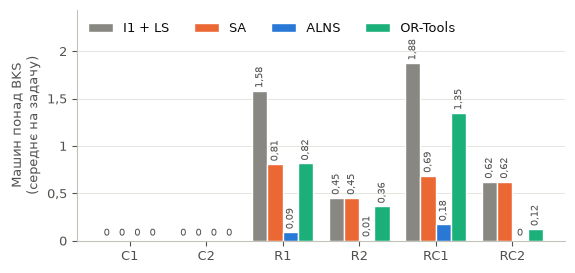

In [5]:
va.fig_vehicles_by_class(exp);

## 3. Відстань на спільних задачах

Спільні задачі — ті, де **кожен** запуск кожного алгоритму має стільки ж машин, скільки BKS.

In [6]:
print(va.common_instances(exp.runs))
va.gap_by_class(exp)

['C101', 'C102', 'C103', 'C104', 'C105', 'C106', 'C107', 'C108', 'C109', 'C201', 'C202', 'C203', 'C204', 'C205', 'C206', 'C207', 'C208', 'R101', 'R201', 'R203', 'R205', 'R206', 'R209', 'R210', 'RC204', 'RC205', 'RC208']


algorithm,I1 + LS,SA,ALNS,OR-Tools,задач
class,,,,,
C1,0.62,-0.00,-0.00,2.28,9.00
C2,1.73,-0.00,-0.00,0.07,8.00
R1,0.83,0.05,0.00,0.17,1.00
R2,12.50,0.96,1.19,3.97,6.00
RC2,15.11,0.50,1.16,4.60,3.00
Усі,5.21,0.27,0.39,2.18,27.00


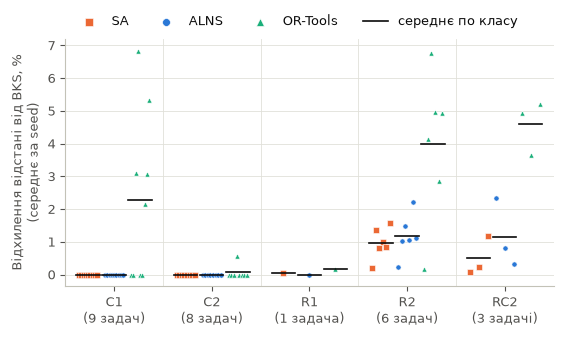

In [7]:
va.fig_gap_by_instance(exp);

## 4. Залежність від seed

In [8]:
va.seed_spread(exp)

,"Задач, де всі seed дали однаковий розв'язок","Задач, де к-сть машин залежить від seed",Стандартне відхилення відстані (медіана по задачах),"Розмах відстані, % від BKS (медіана по задачах)"
SA,18.00,8.00,3.21,0.86
ALNS,18.00,7.00,3.60,0.91
OR-Tools,33.00,5.00,0.00,0.00


## 5. Статистичні тести

Тест Фрідмана порівнює середні ранги алгоритмів по задачах; попарні тести Вілкоксона — з поправкою Голма.

In [9]:
tests = va.rank_tests(exp)
va.rank_summary(tests)

,I1 + LS,SA,ALNS,OR-Tools,задач,χ² Фрідмана,p,"CD (Немені, α = 0.05)"
"Вартість (машини, потім відстань), усі задачі",3.62,2.09,1.50,2.79,56.00,105.28,0.00,0.63
"Кількість машин, усі задачі",3.08,2.56,1.81,2.54,56.00,64.19,0.00,0.63
"Відстань, спільні задачі",3.24,1.93,2.00,2.83,27.00,34.53,0.00,0.90


In [10]:
va.pairwise_table(tests)

A краще  \
критерій                                      A       B                   
Вартість (машини, потім відстань), усі задачі I1 + LS SA              0   
                                                      ALNS            0   
                                                      OR-Tools        5   
                                              SA      ALNS            6   
                                                      OR-Tools       37   
                                              ALNS    OR-Tools       43   
Кількість машин, усі задачі                   I1 + LS SA              0   
                                                      ALNS            0   
                                                      OR-Tools        1   
                                              SA      ALNS            0   
                                                      OR-Tools        8   
                                              ALNS    OR-Tools       22   
Відстань, спільні задачі                      I1 + LS SA              0   
                                                      ALNS            0   
                                                      OR-Tools        4   
                                              SA      ALNS            6   
                                                      OR-Tools       15   
                                              ALNS    OR-Tools       15   

                                                                нічия  \
критерій                                      A       B                 
Вартість (машини, потім відстань), усі задачі I1 + LS SA           12   
                                                      ALNS         12   
                                                      OR-Tools      9   
                                              SA      ALNS         17   
                                                      OR-Tools     11   
                                              ALNS    OR-Tools     11   
Кількість машин, усі задачі                   I1 + LS SA           38   
                                                      ALNS         27   
                                                      OR-Tools     36   
                                              SA      ALNS         30   
                                                      OR-Tools     41   
                                              ALNS    OR-Tools     34   
Відстань, спільні задачі                      I1 + LS SA           12   
                                                      ALNS         12   
                                                      OR-Tools      9   
                                              SA      ALNS         17   
                                                      OR-Tools     11   
                                              ALNS    OR-Tools     11   

                                                                B краще  \
критерій                                      A       B                   
Вартість (машини, потім відстань), усі задачі I1 + LS SA             44   
                                                      ALNS           44   
                                                      OR-Tools       42   
                                              SA      ALNS           33   
                                                      OR-Tools        8   
                                              ALNS    OR-Tools        2   
Кількість машин, усі задачі                   I1 + LS SA             18   
                                                      ALNS           29   
                                                      OR-Tools       19   
                                              SA      ALNS           26   
                                                      OR-Tools        7   
                                              ALNS    OR-Tools        0   
Відстань, спільні задачі                      I1 + L

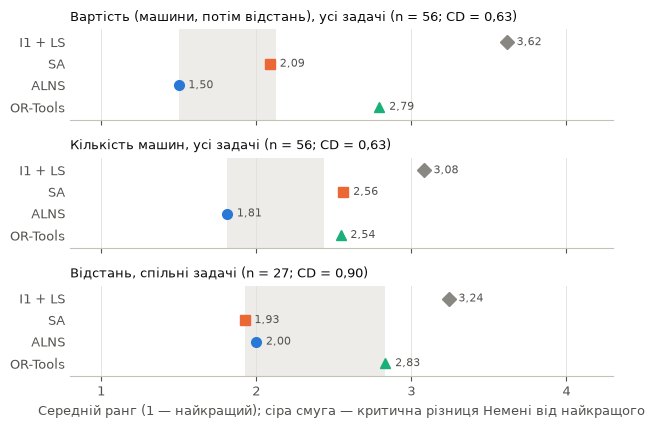

In [11]:
va.fig_ranks(tests);

## 6. Збіжність

Криві — з окремого прогону conv-60s (3 seed). Верхній графік — машини понад BKS (сума по задачах), нижній — відхилення відстані на спільних задачах, з моменту, коли всі запуски мають кількість машин BKS.

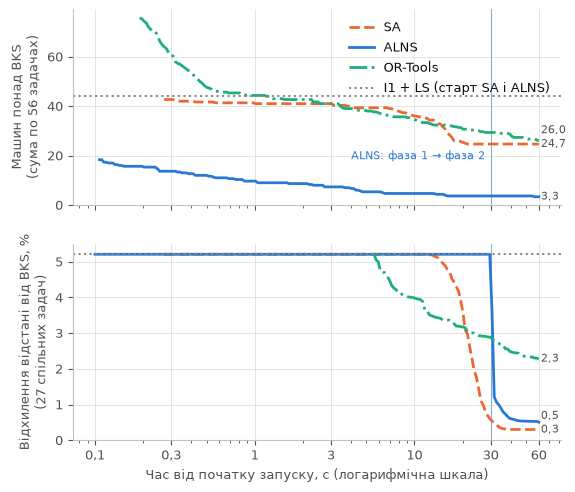

In [12]:
va.fig_convergence(curves, reference=exp);

## 7. Карта маршрутів

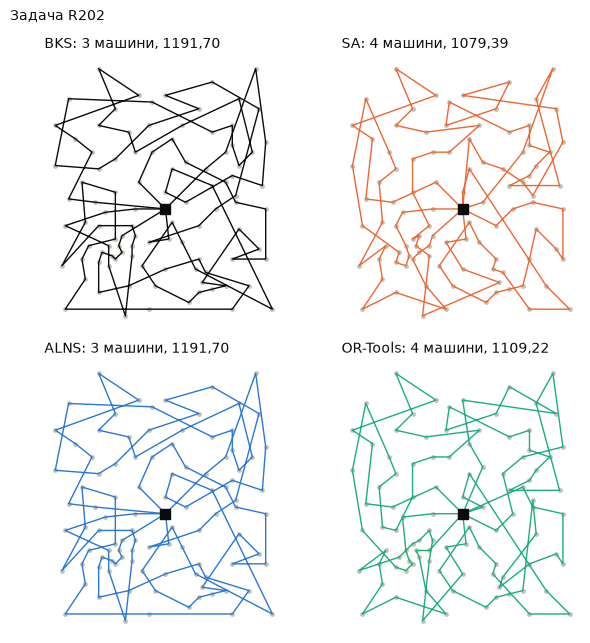

In [13]:
va.fig_routes(exp, 'R202');

## 8. Вплив навантаження на систему (загроза валідності)

In [14]:
va.load_effect(exp)

,Ітерацій за запуск (медіана),Відносна швидкість: мінімум,Відносна швидкість: 5-й перцентиль,Відносна швидкість: 95-й перцентиль,Відносна швидкість: максимум,"Кореляція Спірмена (ітерації, вартість), медіана по задачах","Геп повільніших запусків, %","Геп швидших запусків, %"
SA,"421,540,096.00",0.81,0.93,1.81,1.97,-0.23,0.31,0.27
ALNS,"210,160.50",0.69,0.76,1.56,1.95,-0.15,0.94,0.81


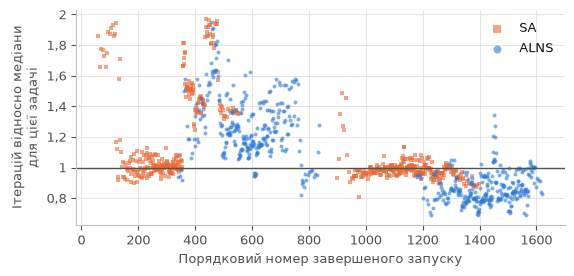

In [15]:
va.fig_load_effect(exp);